# Klasifikasi & Pemetaan Land Use and Land Cover (LULC) Jawa Timur
## Pemodelan Machine Learning Random Forest Berbasis Citra Satelit Sentinel-2 (5 Kelas Tutupan Lahan)

Dokumen notebook ini menyajikan alur kerja pemodelan sains data geospasial secara end-to-end dalam rangka **Klasifikasi Land Use and Land Cover (LULC) Provinsi Jawa Timur** menggunakan citra satelit optik **Sentinel-2A (Level-2A)** dan algoritma **Random Forest Classifier**.

---

### Metodologi & Arsitektur Alur Kerja (CRISP-DM)
Proyek ini mengadopsi standar **CRISP-DM (Cross-Industry Standard Process for Data Mining)** dengan 5 target kelas tutupan lahan pada 276 poligon acuan. Poligon yang tidak memiliki piksel Sentinel-2 valid dikeluarkan dari CSV fitur dan split poligon akhir.
1. **Sawah / Pertanian:** Lahan bercocok tanam musiman.
2. **Pemukiman / Built-Up:** Area perumahan, gedung, jalan, dan infrastruktur buatan.
3. **Hutan Non-Mangrove:** Vegetasi pepohonan daratan / dataran tinggi.
4. **Hutan Mangrove:** Vegetasi ekosistem pesisir dan muara sungai yang terpengaruh pasang surut air laut.
5. **Air (Water Bodies):** Laut, sungai, waduk, dan tambak.

---

### Pencegahan Kebocoran Data (Spatial Autocorrelation Data Leakage)
Untuk meminimalisir bias autokorelasi spasial antar piksel yang berdampingan dalam poligon yang sama, pembagian dataset **70% Training** dan **30% Testing** dilakukan secara ketat pada tingkat **Poligon Sampel (Polygon-Level Stratified Split)** berdasarkan `ID_Poligon`. 

Seluruh piksel dari poligon yang dialokasikan ke data uji (*test set*) tidak pernah terlihat oleh model saat proses pelatihan.

---

### Ekspor Berkas CSV Dataset Split
Seluruh dataset hasil pembagian diekspor ke direktori `data/csv/split_dataset/`:
- `train_polygons.csv` dan `test_polygons.csv` berisi poligon yang memiliki piksel citra valid.
- `train_pixels.csv` dan `test_pixels.csv` dibuat otomatis dari raster di `data/geojson/TILE_1` sampai `TILE_5`.


## 1. Import Library & Pembagian Dataset Poligon (Train vs Test)

Pada tahap ini, kita membaca 276 poligon acuan yang valid dari `data/geojson/jawa_timur.geojson`, memberikan ID unik, lalu membuat split awal terstratifikasi (70:30). Setelah ekstraksi, poligon tanpa piksel raster valid dikeluarkan dan split dihitung ulang pada poligon yang tersisa. GeoJSON menyediakan geometri dan label, bukan nilai band Sentinel-2.


In [1]:
import geopandas as gpd
import pandas as pd
from extract_sentinel_pixels import stratified_polygon_split

# 1. Membaca GeoJSON (jawa_timur.geojson - 276 poligon valid)
gdf = gpd.read_file("data/geojson/jawa_timur.geojson")
if "Type" not in gdf.columns:
    raise ValueError("GeoJSON wajib memiliki kolom kelas 'Type'.")
gdf["Type"] = gdf["Type"].astype(str).str.strip().str.lower()
gdf["Type"] = gdf["Type"].replace({"hutan non mangrovehutan non mangrove": "hutan non mangrove"})
class_names = {
    "sawah": "Sawah",
    "pemukiman": "Pemukiman",
    "hutan mangrove": "Hutan mangrove",
    "hutan non mangrove": "Hutan non mangrove",
    "air": "Air",
}
gdf["Type"] = gdf["Type"].map(class_names)
if gdf["Type"].isna().any():
    raise ValueError("Ditemukan label kelas yang tidak dikenal dalam GeoJSON.")
print("=== TOTAL POLIGON GEODATASET MASUKAN ===")
print(gdf["Type"].value_counts())

# Memberikan ID poligon yang konsisten dengan CSV fitur hasil ekstraksi.
type_counts = {}
id_poligons = []
for t in gdf["Type"]:
    type_counts[t] = type_counts.get(t, 0) + 1
    id_poligons.append(f"{t.replace(' ', '_')}_{type_counts[t]:02d}")
gdf["ID_Poligon"] = id_poligons

# 2. Pembagian stratified 70:30 yang stabil lintas lingkungan.
gdf = stratified_polygon_split(gdf, test_percent=30)

# 3. Simpan Ringkasan CSV Poligon
df_train_poly = gdf[gdf["Status_Split"] == "Training"][["ID_Poligon", "Type", "Status_Split"]].copy()
df_test_poly = gdf[gdf["Status_Split"] == "Testing"][["ID_Poligon", "Type", "Status_Split"]].copy()

df_train_poly.to_csv("data/csv/split_dataset/train_polygons.csv", index=False)
df_test_poly.to_csv("data/csv/split_dataset/test_polygons.csv", index=False)

print("\n=== TABEL CROSS-TABULATION PEMBAGIAN POLIGON (70% vs 30%) ===")
print(pd.crosstab(gdf["Type"], gdf["Status_Split"], margins=True))
print(f"\n[SUCCESS]: File CSV poligon latih ({len(df_train_poly)}) & uji ({len(df_test_poly)}) berhasil disimpan.")


=== TOTAL POLIGON GEODATASET MASUKAN ===
Type
Hutan non mangrove    64
Pemukiman             62
Air                   56
Sawah                 52
Hutan mangrove        42
Name: count, dtype: int64

=== TABEL CROSS-TABULATION PEMBAGIAN POLIGON (70% vs 30%) ===
Status_Split        Testing  Training  All
Type                                      
Air                      17        39   56
Hutan mangrove           13        29   42
Hutan non mangrove       19        45   64
Pemukiman                19        43   62
Sawah                    15        37   52
All                      83       193  276

[SUCCESS]: File CSV poligon latih (193) & uji (83) berhasil disimpan.


## 2. Ekstraksi Fitur Spektral & Indeks Satelit

Untuk meningkatkan daya pisah antar kelas tutupan lahan, kita mengekstrak 5 band spektral utama Sentinel-2 (`B02 Blue`, `B03 Green`, `B04 Red`, `B08 NIR`, `B11 SWIR1`) dan menghitung 3 Indeks Spektral Kunci:

1. **Normalized Difference Vegetation Index (NDVI):**
   $$\text{NDVI} = \frac{\text{B08} - \text{B04}}{\text{B08} + \text{B04}}$$
   *Mengukur kerapatan dan tingkat kehijauan vegetasi kanopi.*

2. **Normalized Difference Water Index (NDWI):**
   $$\text{NDWI} = \frac{\text{B03} - \text{B08}}{\text{B03} + \text{B08}}$$
   *Memisahkan badan air dari area daratan.*

3. **Normalized Difference Built-up Index (NDBI):**
   $$\text{NDBI} = \frac{\text{B11} - \text{B08}}{\text{B11} + \text{B08}}$$
   *Mengidentifikasi kawasan permukiman dan material bangunan buatan.*

Band B02, B03, B04, B08, dan B11 diekstrak dari folder `TILE_1`–`TILE_5` pada piksel di dalam poligon. Ekstraksi JP2 memerlukan paket `rasterio`. B11 (20 m) di-resample bilinear ke grid 10 m; jika satu tile tersedia dari beberapa tanggal, akuisisi terbaru dipakai. Piksel bernilai nol dibuang dan maksimal 50 piksel valid dipilih secara deterministik per poligon. Poligon tanpa data raster valid dikeluarkan dari CSV split. Cloud masking tidak dilakukan karena file SCL tidak disediakan.


In [2]:
# Ekstrak fitur piksel dari raster Sentinel-2 dan simpan CSV split terbaru.
from pathlib import Path
from extract_sentinel_pixels import FEATURES, create_pixel_datasets

df_train_pixels, df_test_pixels, df_train_poly, df_test_poly = create_pixel_datasets(
    gdf,
    df_train_poly,
    df_test_poly,
    Path("data/geojson"),
    Path("data/csv/split_dataset"),
)
features = FEATURES
X_train, y_train = df_train_pixels[features], df_train_pixels["Type"]
X_test, y_test = df_test_pixels[features], df_test_pixels["Type"]
print("\n=== LIMA BARIS PERTAMA DATA FITUR TRAINING ===")
print(X_train.head())


=== SCENE SENTINEL-2 YANG DIPAKAI ===
T49MEM: 20260929T023531
T49MFM: 20261001T024141
T49MFN: 20261001T024141
T49MGM: 20261001T022529



=== PEMBAGIAN POLIGON FINAL SETELAH FILTER CAKUPAN RASTER ===
Status_Split        Testing  Training  All
Type                                      
Air                      16        39   55
Hutan mangrove           13        29   42
Hutan non mangrove       19        44   63
Pemukiman                 9        20   29
Sawah                    16        36   52
All                      73       168  241


[WARNING] 35 poligon tidak memiliki piksel valid pada tile yang tersedia dan tidak dimasukkan ke CSV split:
           ID_Poligon               Type Status_Split
               Air_44                Air     Training
         Pemukiman_12          Pemukiman     Training
         Pemukiman_20          Pemukiman     Training
         Pemukiman_21          Pemukiman      Testing
         Pemukiman_22          Pemukiman     Training
         Pemukiman_23          Pemukiman     Training
         Pemukiman_24          Pemukiman     Training
         Pemukiman_25          Pemukiman     Training
         Pemukiman_26          Pemukiman     Training
         Pemukiman_27          Pemukiman     Training
         Pemukiman_28          Pemukiman      Testing
         Pemukiman_29          Pemukiman     Training
         Pemukiman_30          Pemukiman     Training
         Pemukiman_31          Pemukiman      Testing
         Pemukiman_32          Pemukiman      Testing
         Pemukiman_33       

## 3. Pelatihan Model Random Forest Classifier

**Random Forest** dipilih karena merupakan algoritma ensemble berbasis decision trees yang sangat tangguh terhadap data geospasial non-linear dan mampu menangani korelasi antar-band spektral tanpa asumsi distribusi normal.

### Konfigurasi Hiperparameter:
- `n_estimators = 100`: Menggunakan 100 pohon keputusan independen.
- `criterion = 'gini'`: Mengukur tingkat kemurnian pemisahan cabang (*impurity split*).
- `random_state = 42`: Memastikan hasil eksperimen dapat direproduksi secara konsisten (*reproducibility*).


In [3]:
from sklearn.ensemble import RandomForestClassifier
import joblib

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
joblib.dump(rf_model, "data/model_rf_lulc.joblib")
print(f"[SUCCESS]: Model Random Forest Classifier disimpan dari {len(X_train):,} piksel data latih.")


[SUCCESS]: Model Random Forest Classifier disimpan dari 7,802 piksel data latih.


## 4. Evaluasi Performa Model pada Data Uji (Unseen Test Data)

Model dievaluasi menggunakan data uji piksel dari poligon independen yang tidak pernah digunakan dalam proses pelatihan.

Metrik evaluasi yang dihitung meliputi:
1. **Overall Accuracy:** Persentase total prediksi benar terhadap seluruh piksel sampel.
2. **Cohen's Kappa Score:** Mengukur tingkat kesepakatan prediksi dengan mengeliminasi faktor kebetulan (*chance agreement*).
3. **Confusion Matrix:** Detail matriks klasifikasi benar dan salah antar kelas.
4. **Precision, Recall, F1-Score:** Metrik evaluasi per kelas tutupan lahan.


             RINGKASAN METRIK EVALUASI             
Overall Accuracy : 79.88%
Cohen's Kappa    : 0.7440

=== CLASSIFICATION REPORT DETIL PER KELAS ===
                    precision    recall  f1-score   support

               Air       0.79      0.75      0.77       739
    Hutan mangrove       0.85      0.75      0.80       584
Hutan non mangrove       0.84      0.87      0.85       950
         Pemukiman       0.79      0.73      0.76       450
             Sawah       0.72      0.85      0.78       627

          accuracy                           0.80      3350
         macro avg       0.80      0.79      0.79      3350
      weighted avg       0.80      0.80      0.80      3350



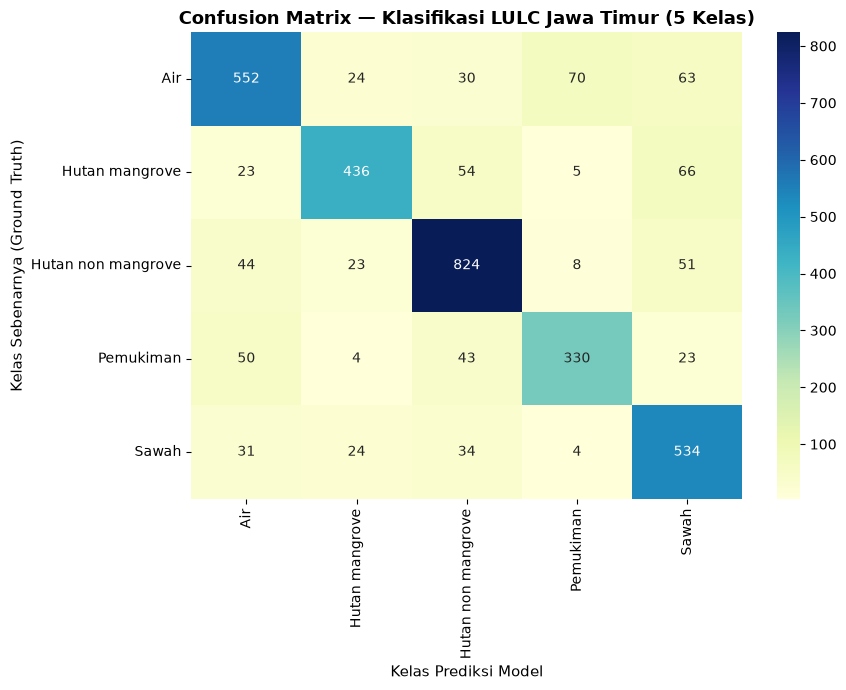

In [4]:
from sklearn.metrics import accuracy_score, cohen_kappa_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)

print("==================================================")
print("             RINGKASAN METRIK EVALUASI             ")
print("==================================================")
print(f"Overall Accuracy : {accuracy * 100:.2f}%")
print(f"Cohen's Kappa    : {kappa:.4f}\n")
print("=== CLASSIFICATION REPORT DETIL PER KELAS ===")
print(classification_report(y_test, y_pred))

labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix — Klasifikasi LULC Jawa Timur (5 Kelas)", fontsize=13, fontweight='bold')
plt.xlabel("Kelas Prediksi Model", fontsize=11)
plt.ylabel("Kelas Sebenarnya (Ground Truth)", fontsize=11)
plt.tight_layout()
plt.show()


## 5. Analisis Tingkat Kepentingan Fitur Spektral (Feature Importances)

Analisis ini memberikan wawasan ilmiah mengenai band atau indeks spektral mana yang paling berkontribusi dalam membedakan ke-5 kelas tutupan lahan (khususnya membedakan Hutan Mangrove dengan Hutan Darat dan Pemukiman).


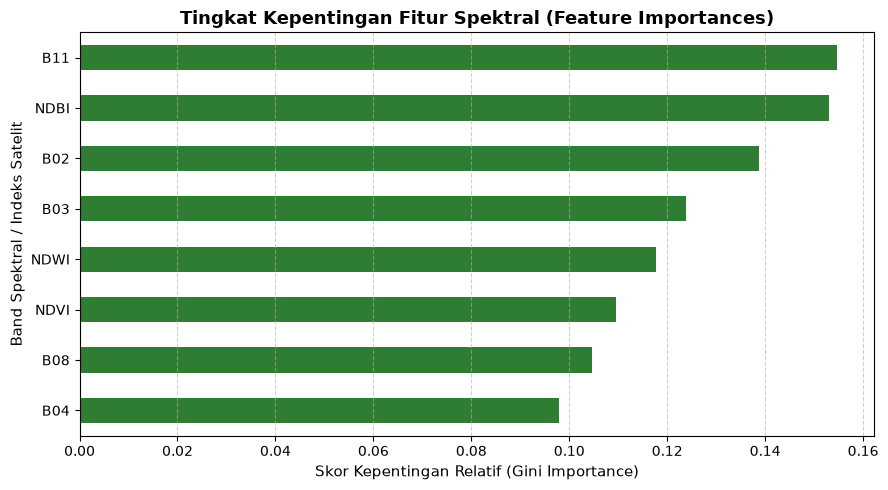

In [5]:
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)
plt.figure(figsize=(9, 5))
importances.plot(kind="barh", color="#2e7d32")
plt.title("Tingkat Kepentingan Fitur Spektral (Feature Importances)", fontsize=13, fontweight='bold')
plt.xlabel("Skor Kepentingan Relatif (Gini Importance)", fontsize=11)
plt.ylabel("Band Spektral / Indeks Satelit", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


## 6. Kesimpulan & Penyiapan Deployment Streamlit

### Rangkuman Temuan Utama:
1. **Pentingnya Band SWIR (B11) & NIR (B08):** Band SWIR1 dan NIR merupakan fitur paling dominan dalam membedakan Hutan Mangrove dari Hutan Non-Mangrove karena tingkat kebasahan substrat tanah pantai yang signifikan.
2. **Pemisahan Data:** Poligon train dan test tidak saling tumpang tindih; seluruh piksel dari satu poligon tetap berada pada split yang sama.
3. **Status Model:** Fitur Sentinel-2 diekstrak dari TILE_1–TILE_5; poligon tanpa cakupan raster valid tidak dipakai. Metrik evaluasi di bawah hanya berlaku untuk sampel dan tanggal citra ini.
